In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

## 1. Load the data

In [2]:
df = pd.read_csv("fastfood.csv")
print(df.shape)
df.head()

(515, 17)


,restaurant,item,calories,cal_fat,total_fat,sat_fat,trans_fat,cholesterol,sodium,total_carb,fiber,sugar,protein,vit_a,vit_c,calcium,salad
0,Mcdonalds,Artisan Grilled Chicken Sandwich,380,60,7,2.0,0.0,95,1110,44,3.0,11,37.0,4.0,20.0,20.0,Other
1,Mcdonalds,Single Bacon Smokehouse Burger,840,410,45,17.0,1.5,130,1580,62,2.0,18,46.0,6.0,20.0,20.0,Other
2,Mcdonalds,Double Bacon Smokehouse Burger,1130,600,67,27.0,3.0,220,1920,63,3.0,18,70.0,10.0,20.0,50.0,Other
3,Mcdonalds,Grilled Bacon Smokehouse Chicken Sandwich,750,280,31,10.0,0.5,155,1940,62,2.0,18,55.0,6.0,25.0,20.0,Other
4,Mcdonalds,Crispy Bacon Smokehouse Chicken Sandwich,920,410,45,12.0,0.5,120,1980,81,4.0,18,46.0,6.0,20.0,20.0,Other


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 515 entries, 0 to 514
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   restaurant   515 non-null    str    
 1   item         515 non-null    str    
 2   calories     515 non-null    int64  
 3   cal_fat      515 non-null    int64  
 4   total_fat    515 non-null    int64  
 5   sat_fat      515 non-null    float64
 6   trans_fat    515 non-null    float64
 7   cholesterol  515 non-null    int64  
 8   sodium       515 non-null    int64  
 9   total_carb   515 non-null    int64  
 10  fiber        503 non-null    float64
 11  sugar        515 non-null    int64  
 12  protein      514 non-null    float64
 13  vit_a        301 non-null    float64
 14  vit_c        305 non-null    float64
 15  calcium      305 non-null    float64
 16  salad        515 non-null    str    
dtypes: float64(7), int64(7), str(3)
memory usage: 68.5 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
calories,515.0,530.912621,282.436147,20.0,330.0,490.0,690.0,2430.0
cal_fat,515.0,238.813592,166.407510,0.0,120.0,210.0,310.0,1270.0
total_fat,515.0,26.590291,18.411876,0.0,14.0,23.0,35.0,141.0
sat_fat,515.0,8.153398,6.418811,0.0,4.0,7.0,11.0,47.0
trans_fat,515.0,0.465049,0.839644,0.0,0.0,0.0,1.0,8.0
cholesterol,515.0,72.456311,63.160406,0.0,35.0,60.0,95.0,805.0
sodium,515.0,1246.737864,689.954278,15.0,800.0,1110.0,1550.0,6080.0
total_carb,515.0,45.664078,24.883342,0.0,28.5,44.0,57.0,156.0
fiber,503.0,4.137177,3.037460,0.0,2.0,3.0,5.0,17.0
sugar,515.0,7.262136,6.761301,0.0,3.0,6.0,9.0,87.0


## 2. Data quality

In [5]:
missing = df.isna().sum()
missing = missing[missing > 0].to_frame("missing")
missing["pct"] = (missing["missing"] / len(df) * 100).round(1)
missing

,missing,pct
fiber,12,2.3
protein,1,0.2
vit_a,214,41.6
vit_c,210,40.8
calcium,210,40.8


Vitamin A, Vitamin C and calcium are missing for about 40% of items (mostly some chains do not report them), so they are left out of the main comparisons. Fiber and protein have only a handful of gaps.

The `salad` column is also checked below.

In [6]:
print(df["salad"].value_counts())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate restaurant+item:", df.duplicated(["restaurant", "item"]).sum())
print()
print("Missing vitamin data by restaurant (share of items):")
(df.groupby("restaurant")[["vit_a", "vit_c", "calcium"]]
   .apply(lambda g: g.isna().mean().round(2)))

salad
Other    515
Name: count, dtype: int64
Duplicate rows: 2
Duplicate restaurant+item: 2

Missing vitamin data by restaurant (share of items):


,vit_a,vit_c,calcium
restaurant,,,
Arbys,0.55,0.55,0.55
Burger King,1.00,1.00,1.00
Chick Fil-A,0.22,0.07,0.07
Dairy Queen,0.36,0.36,0.36
Mcdonalds,0.00,0.00,0.00
Sonic,0.08,0.08,0.08
Subway,0.00,0.00,0.00
Taco Bell,0.77,0.77,0.77


`salad` has a single value (`Other`), so it carries no information and is dropped. Core nutrient columns are used for analysis; the sparse vitamin columns are kept aside.

In [7]:
data = df.drop(columns=["salad"]).copy()
data["restaurant"] = data["restaurant"].replace({"Mcdonalds": "McDonald's"})

# Fill the few missing fiber/protein values with the restaurant median
for col in ["fiber", "protein"]:
    data[col] = data[col].fillna(data.groupby("restaurant")[col].transform("median"))

core = ["calories", "cal_fat", "total_fat", "sat_fat", "trans_fat",
        "cholesterol", "sodium", "total_carb", "fiber", "sugar", "protein"]
print(data[core].isna().sum().sum(), "missing values left in core columns")

0 missing values left in core columns


## 3. Overview by restaurant

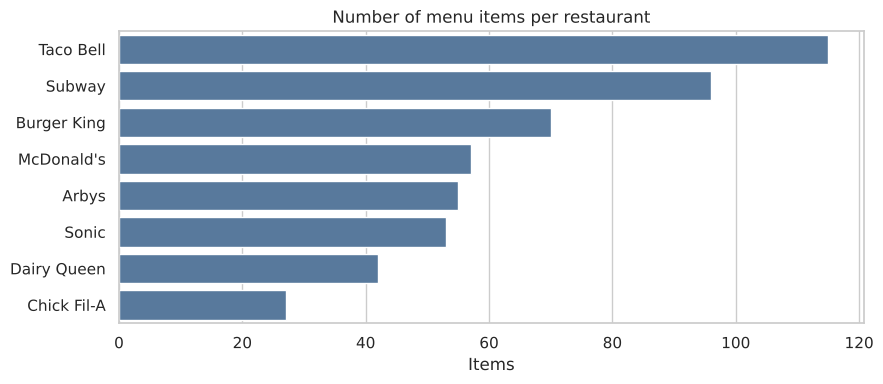

In [8]:
order = data.groupby("restaurant")["calories"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(9, 4))
sns.countplot(data=data, y="restaurant", order=data["restaurant"].value_counts().index, color="#4C78A8", ax=ax)
ax.set_title("Number of menu items per restaurant")
ax.set_xlabel("Items"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [9]:
summary = (data.groupby("restaurant")[["calories", "total_fat", "sodium", "sugar", "protein"]]
           .mean().round(1).loc[order])
summary

,calories,total_fat,sodium,sugar,protein
restaurant,,,,,
Sonic,631.7,37.6,1350.8,6.5,29.2
Burger King,608.6,36.8,1223.6,8.2,30.0
Arbys,532.7,27.0,1515.3,7.6,29.3
McDonald's,640.4,31.8,1437.9,11.1,40.3
Dairy Queen,520.2,28.9,1181.8,6.4,24.8
Subway,503.0,18.5,1273.0,10.1,30.3
Taco Bell,443.7,20.9,1013.9,3.7,17.4
Chick Fil-A,384.4,16.1,1151.5,4.1,31.7


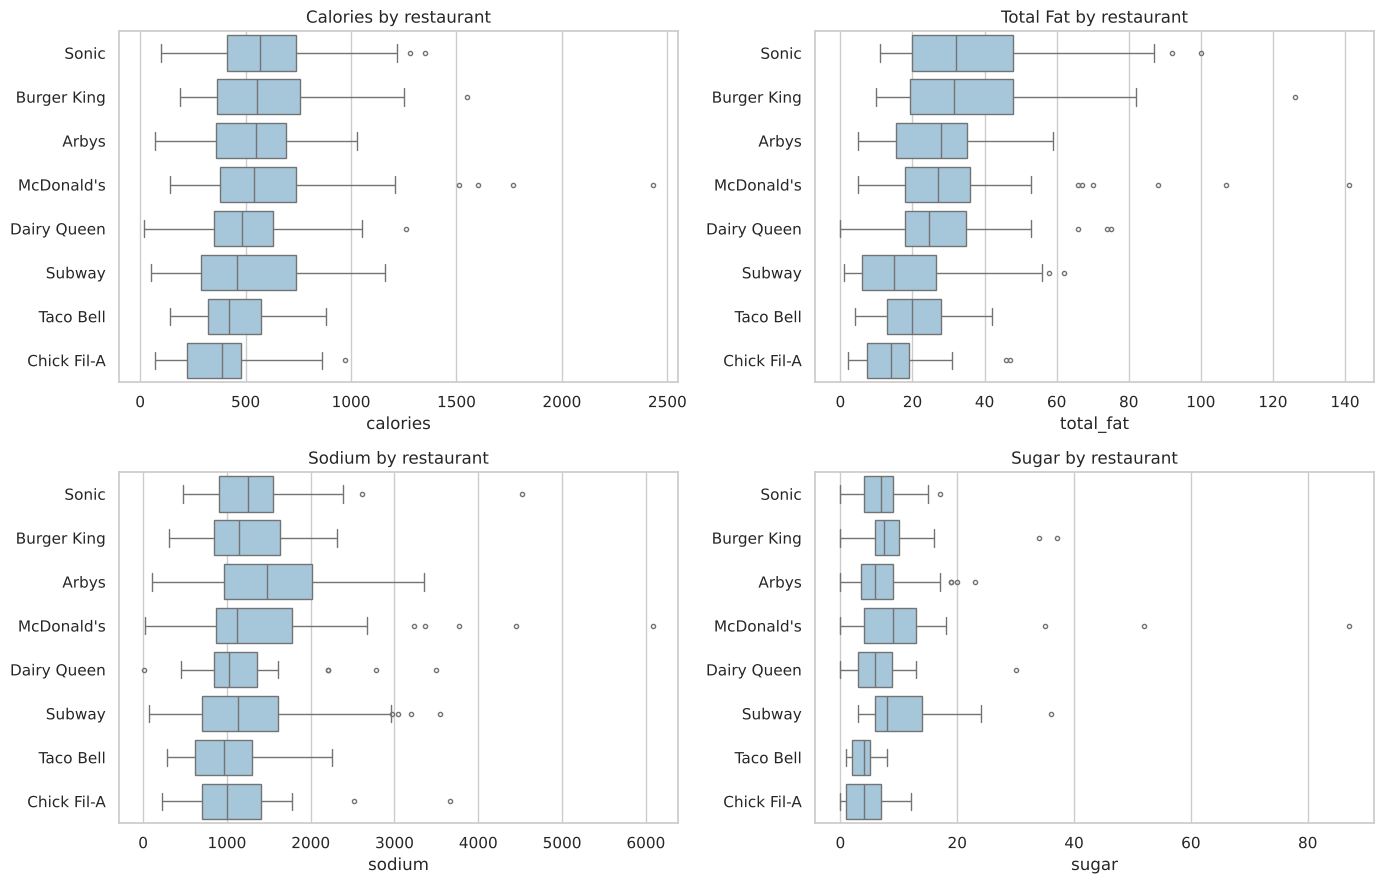

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), ["calories", "total_fat", "sodium", "sugar"]):
    sns.boxplot(data=data, y="restaurant", x=col, order=order, color="#9ecae1", ax=ax, fliersize=3)
    ax.set_title(f"{col.replace('_', ' ').title()} by restaurant")
    ax.set_ylabel("")
plt.tight_layout(); plt.show()

## 4. Distributions

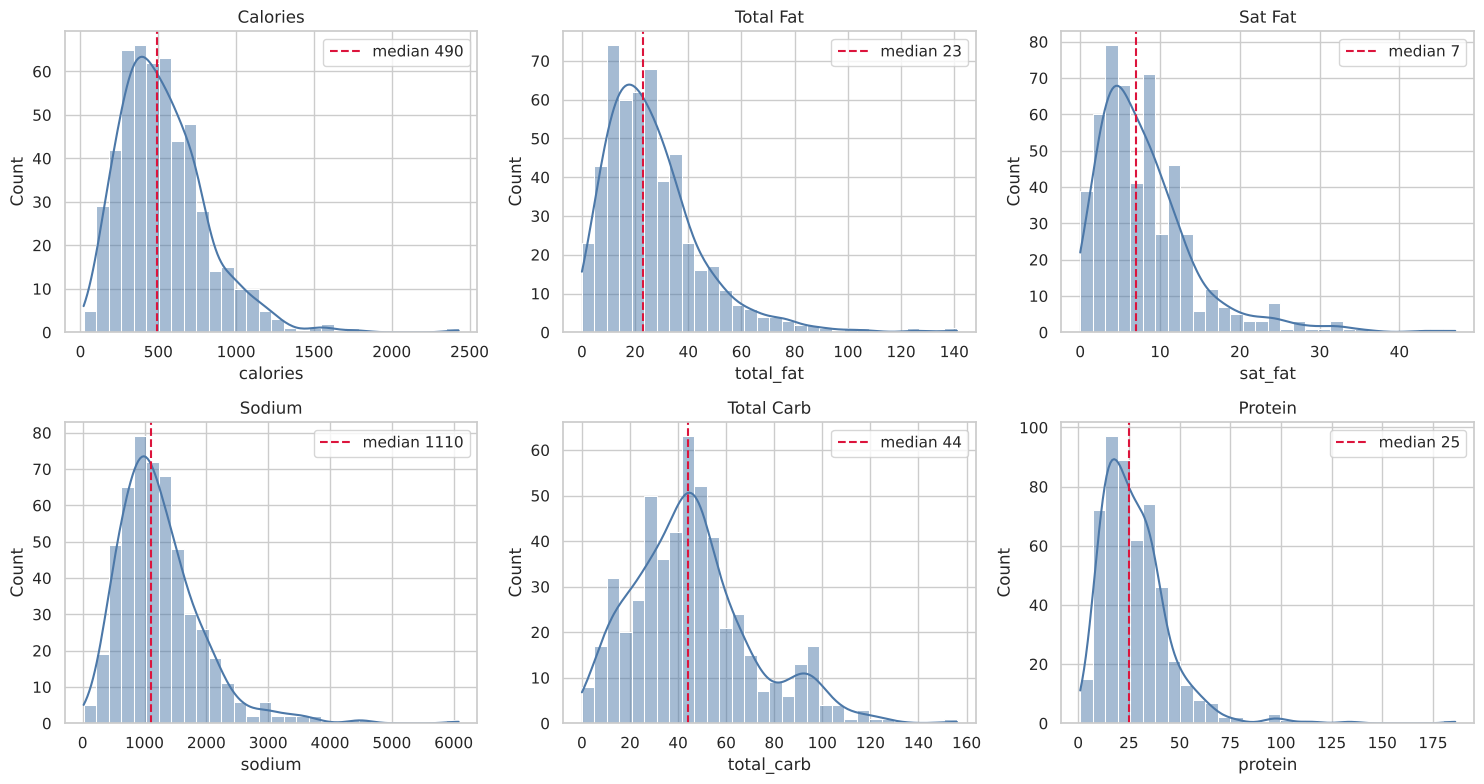

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ["calories", "total_fat", "sat_fat", "sodium", "total_carb", "protein"]):
    sns.histplot(data[col], bins=30, kde=True, color="#4C78A8", ax=ax)
    ax.axvline(data[col].median(), color="crimson", ls="--", label=f"median {data[col].median():.0f}")
    ax.set_title(col.replace("_", " ").title())
    ax.legend()
plt.tight_layout(); plt.show()

## 5. Highest and lowest items

In [12]:
print("Top 10 items by calories")
display(data.nlargest(10, "calories")[["restaurant", "item", "calories", "total_fat", "sodium"]])

print("Top 10 items by sodium (mg)")
display(data.nlargest(10, "sodium")[["restaurant", "item", "sodium", "calories"]])

print("Top 10 items by sugar (g)")
display(data.nlargest(10, "sugar")[["restaurant", "item", "sugar", "calories"]])

Top 10 items by calories


,restaurant,item,calories,total_fat,sodium
39,McDonald's,20 piece Buttermilk Crispy Chicken Tenders,2430,141,6080
44,McDonald's,40 piece Chicken McNuggets,1770,107,3370
47,McDonald's,10 piece Sweet N' Spicy Honey BBQ Glazed Tenders,1600,66,4450
192,Burger King,American Brewhouse King,1550,126,1820
38,McDonald's,12 piece Buttermilk Crispy Chicken Tenders,1510,88,3770
115,Sonic,Garlic Parmesan Dunked Ultimate Chicken Sandwich,1350,100,2180
98,Sonic,Super Sonic Bacon Double Cheeseburger (w/mayo),1280,92,1630
270,Dairy Queen,6 Piece Chicken Strip Basket w/ Country Gravy,1260,66,3500
211,Burger King,Rodeo King,1250,82,2270
101,Sonic,Super Sonic Double Cheeseburger W/ Mayo,1220,87,1520


Top 10 items by sodium (mg)


,restaurant,item,sodium,calories
39,McDonald's,20 piece Buttermilk Crispy Chicken Tenders,6080,2430
114,Sonic,Buffalo Dunked Ultimate Chicken Sandwich,4520,1000
47,McDonald's,10 piece Sweet N' Spicy Honey BBQ Glazed Tenders,4450,1600
38,McDonald's,12 piece Buttermilk Crispy Chicken Tenders,3770,1510
69,Chick Fil-A,30 piece Chicken Nuggets,3660,970
326,Subway,Footlong Corned Beef Reuben,3540,940
270,Dairy Queen,6 Piece Chicken Strip Basket w/ Country Gravy,3500,1260
44,McDonald's,40 piece Chicken McNuggets,3370,1770
155,Arbys,Half Pound French Dip & Swiss,3350,750
37,McDonald's,10 piece Buttermilk Crispy Chicken Tenders,3230,1210


Top 10 items by sugar (g)


,restaurant,item,sugar,calories
47,McDonald's,10 piece Sweet N' Spicy Honey BBQ Glazed Tenders,87,1600
46,McDonald's,6 piece Sweet N' Spicy Honey BBQ Glazed Tenders,52,960
229,Burger King,"Chicken, Apple & Cranberry Salad w/ Crispy Chi...",37,700
351,Subway,Footlong Sweet Onion Chicken Teriyaki,36,760
45,McDonald's,4 piece Sweet N' Spicy Honey BBQ Glazed Tenders,35,640
228,Burger King,"Chicken, Apple & Cranberry Salad w/ Grilled Ch...",34,560
280,Dairy Queen,Large Cheese Curds,30,1050
326,Subway,Footlong Corned Beef Reuben,24,940
332,Subway,Footlong Meatball Marinara,24,960
138,Arbys,Arby-Q Sandwich,23,400


In [13]:
low = data[data["calories"] > 0].nsmallest(10, "calories")
low[["restaurant", "item", "calories", "total_fat", "protein"]]

,restaurant,item,calories,total_fat,protein
302,Dairy Queen,Side Salad,20,0,1.0
392,Subway,Veggie Delite Salad,50,1,3.0
72,Chick Fil-A,4 Piece Grilled Chicken Nuggets,70,2,13.0
187,Arbys,Chopped Side Salad,70,5,5.0
127,Sonic,Ultimate Chicken Club,100,64,39.0
73,Chick Fil-A,6 Piece Grilled Chicken Nuggets,110,3,19.0
372,Subway,Black Forest Ham Salad,110,3,12.0
390,Subway,Turkey Breast & Ham Salad,110,3,12.0
391,Subway,Turkey Breast Salad,110,2,12.0
60,Chick Fil-A,1 Piece Chick-n-Strips,120,6,11.0


## 6. Relationships between nutrients

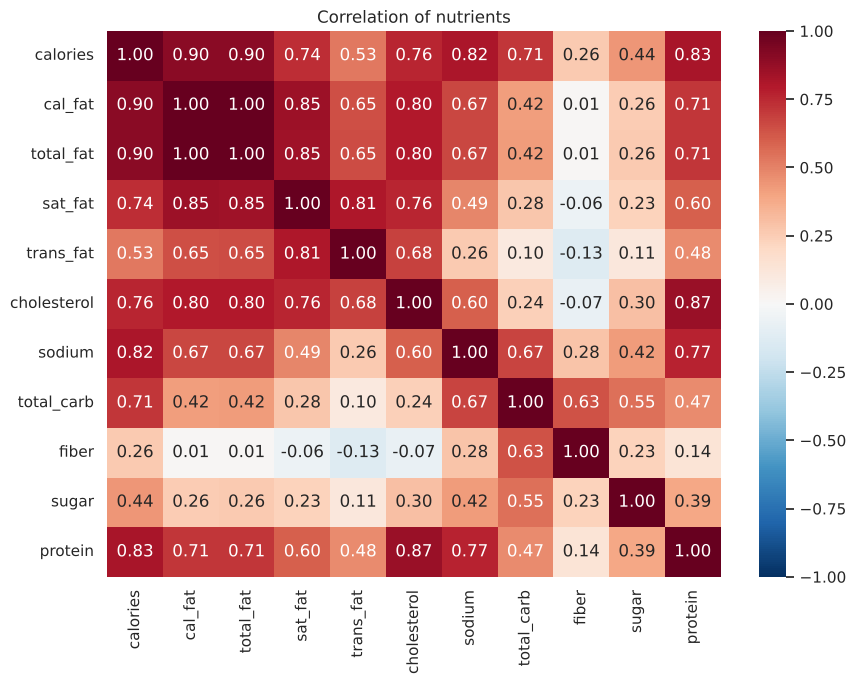

In [14]:
corr = data[core].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation of nutrients")
plt.tight_layout(); plt.show()

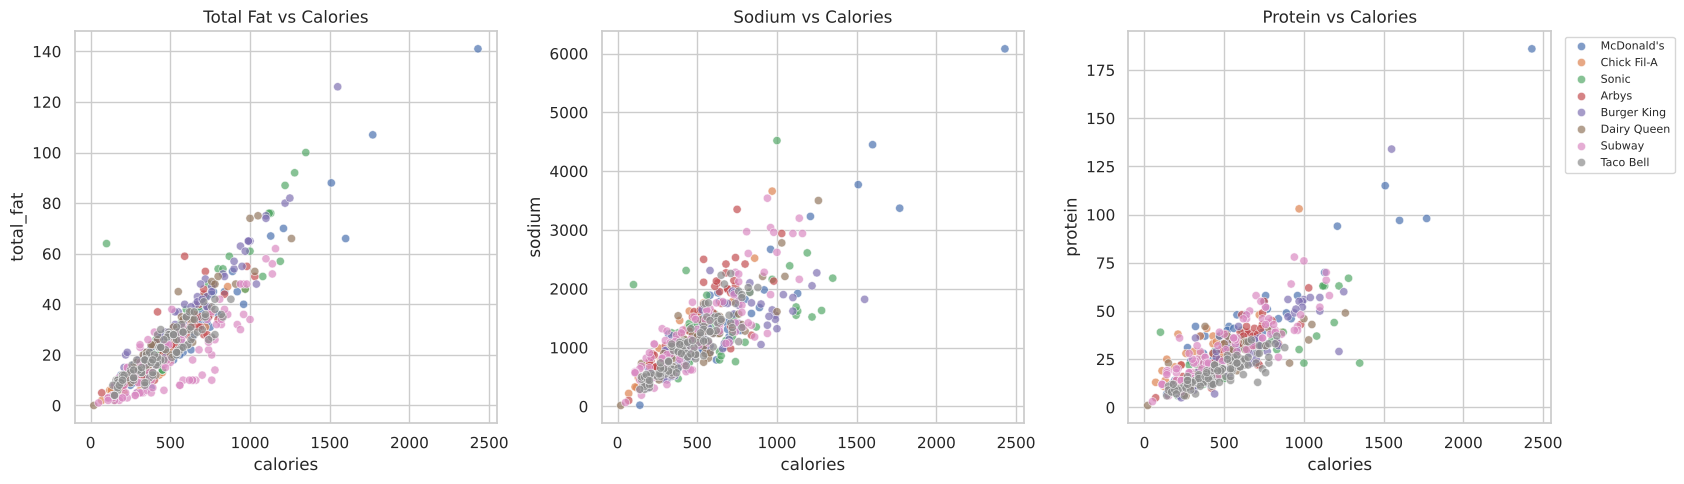

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (x, y) in zip(axes, [("calories", "total_fat"), ("calories", "sodium"), ("calories", "protein")]):
    sns.scatterplot(data=data, x=x, y=y, hue="restaurant", alpha=0.7, s=35, ax=ax, legend=(ax is axes[-1]))
    ax.set_title(f"{y.replace('_', ' ').title()} vs {x.title()}")
axes[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

Calories track total fat and carbohydrate strongly; sodium is related to calories too, but with much more spread between items.

## 7. Protein efficiency and daily-limit check

In [16]:
# Protein per 100 calories, excluding near-zero calorie items (drinks, condiments)
food = data[data["calories"] >= 100].copy()
food["protein_per_100cal"] = (food["protein"] / food["calories"] * 100).round(2)

best = food.nlargest(10, "protein_per_100cal")[["restaurant", "item", "calories", "protein", "protein_per_100cal"]]
best

,restaurant,item,calories,protein,protein_per_100cal
127,Sonic,Ultimate Chicken Club,100,39.0,39.00
75,Chick Fil-A,12 Piece Grilled Chicken Nuggets,210,38.0,18.10
74,Chick Fil-A,8 piece Grilled Chicken Nuggets,140,25.0,17.86
73,Chick Fil-A,6 Piece Grilled Chicken Nuggets,110,19.0,17.27
378,Subway,Double Chicken Salad,220,36.0,16.36
299,Dairy Queen,Grilled Chicken Garden Greens Salad,150,23.0,15.33
382,Subway,Oven Roasted Chicken Salad,140,19.0,13.57
52,McDonald's,Premium Bacon Ranch Salad w/ Grilled Chicken,320,42.0,13.12
383,Subway,Roast Beef Salad,140,18.0,12.86
375,Subway,Carved Turkey Salad,150,19.0,12.67


In [17]:
# Share of items exceeding common daily reference values in a single item
limits = {"sodium > 2300 mg": data["sodium"] > 2300,
          "sodium > 1500 mg": data["sodium"] > 1500,
          "sat fat > 20 g": data["sat_fat"] > 20,
          "calories > 1000": data["calories"] > 1000}

share = pd.DataFrame({name: data.assign(flag=mask).groupby("restaurant")["flag"].mean().mul(100).round(1)
                      for name, mask in limits.items()}).loc[order]
share

,sodium > 2300 mg,sodium > 1500 mg,sat fat > 20 g,calories > 1000
restaurant,,,,
Sonic,7.5,32.1,11.3,15.1
Burger King,1.4,32.9,17.1,8.6
Arbys,10.9,49.1,0.0,1.8
McDonald's,10.5,33.3,5.3,10.5
Dairy Queen,4.8,19.0,11.9,7.1
Subway,9.4,28.1,1.0,4.2
Taco Bell,0.0,15.7,0.0,0.0
Chick Fil-A,7.4,22.2,0.0,0.0


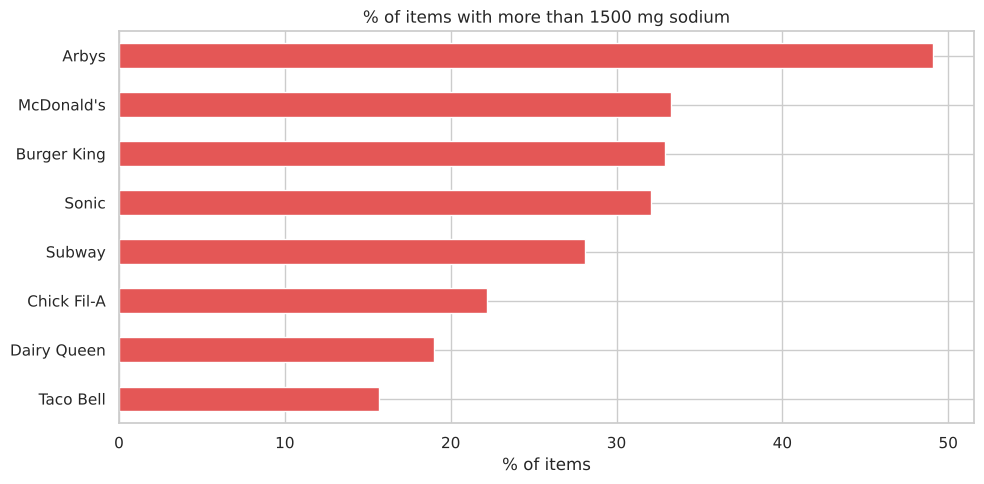

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))
share["sodium > 1500 mg"].sort_values().plot.barh(color="#E45756", ax=ax)
ax.set_title("% of items with more than 1500 mg sodium")
ax.set_xlabel("% of items"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

## 8. Restaurant scorecard

In [19]:
score = (data.groupby("restaurant")
         .agg(items=("item", "count"),
              avg_calories=("calories", "mean"),
              avg_sodium=("sodium", "mean"),
              avg_sugar=("sugar", "mean"),
              avg_protein=("protein", "mean"))
         .round(1))
score["protein_per_100cal"] = (score["avg_protein"] / score["avg_calories"] * 100).round(2)
score.sort_values("avg_calories", ascending=False)

,items,avg_calories,avg_sodium,avg_sugar,avg_protein,protein_per_100cal
restaurant,,,,,,
McDonald's,57,640.4,1437.9,11.1,40.3,6.29
Sonic,53,631.7,1350.8,6.5,29.2,4.62
Burger King,70,608.6,1223.6,8.2,30.0,4.93
Arbys,55,532.7,1515.3,7.6,29.3,5.50
Dairy Queen,42,520.2,1181.8,6.4,24.8,4.77
Subway,96,503.0,1273.0,10.1,30.3,6.02
Taco Bell,115,443.7,1013.9,3.7,17.4,3.92
Chick Fil-A,27,384.4,1151.5,4.1,31.7,8.25


## 9. Key takeaways

- **Highest calories:** McDonald's (about 640 on average) and Sonic (about 630). Chick-fil-A (about 384) and Taco Bell (about 444) are lowest.
- **Highest sodium:** Arby's (about 1,515 mg) and McDonald's (about 1,438 mg) average the most per item. 30 items exceed 2,300 mg, a full day's limit, in one item.
- **Best protein per calorie:** Chick-fil-A (about 8.2 g per 100 kcal), then McDonald's and Subway. Taco Bell is lowest (about 3.9).
- **Relationships:** calories correlate most with total fat (0.90), then protein (0.83), sodium (0.82) and carbs (0.71).
- **Biggest items:** large shareable portions such as McDonald's 20-piece tenders (2,430 kcal) dominate the top of the calorie ranking.

**Notes and limits**
- Vitamin/calcium columns are missing for roughly 40% of items and were not analysed.
- `salad` contains only one value and was dropped.
- Missing fiber/protein values were filled with the restaurant median.
- Values are per item as listed, not per 100 g, so larger items naturally score higher.